In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
cd /content/drive/MyDrive/dog-breed

/content/drive/MyDrive/dog-breed


In [3]:
ls

artifacts/  data/                       figures/    splits.json
crops/      dog_breed_experiment.ipynb  labels.csv


# Dog Breed Identification — Empirical Essay

**Headline experiment:** *does cropping the dog out (removing background) improve fine-grained breed classification?*

**Ladder of runs**
- **E0**: ResNet-50 *frozen* + linear head — what does ImageNet alone give us?
- **E1**: ResNet-50 fine-tuned — how much does fine-tuning add?
- **E2**: ConvNeXt-Base @ 384, full image — how much does a stronger backbone + higher-res add?
- **E3**: ConvNeXt-Base @ 384, **cropped** image — does removing background help? (headline)

**Splits**: stratified 60 / 20 / 20 train / val / test (~51 / 17 / 17 images per class).

**Detector**: Grounding-DINO with prompt `"a dog ."` (breed-agnostic on purpose).

**Metrics**: log-loss (primary), top-1, top-5, macro-F1, ECE.

*Caveat — pretraining overlap*: this dataset is a subset of ImageNet (Stanford Dogs); ImageNet-pretrained backbones have likely seen some of these images. Absolute scores are inflated; **relative deltas between E0–E3 stay valid** because every run shares the same leakage.

## Section 0 — Setup

In [4]:
# Pinned installs. Run once per Colab session.
!pip install -q torch torchvision timm albumentations transformers scikit-learn pandas matplotlib seaborn pillow tqdm

In [27]:
import os, json, random, math
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, accuracy_score, confusion_matrix, f1_score

import timm
from timm.data import Mixup, create_transform
from timm.loss import SoftTargetCrossEntropy

import gc


In [28]:
# Reproducibility, paths, plotting style, output helpers.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DRIVE_DIR = Path('.')
SCRATCH   = Path('.')
TRAIN_DIR = SCRATCH / 'data'
CROP_DIR  = SCRATCH / 'crops'
FIG_DIR   = SCRATCH / 'figures'
ART_DIR   = SCRATCH / 'artifacts'
SPLITS_PATH = SCRATCH / 'splits.json'
for p in [SCRATCH, FIG_DIR, ART_DIR, CROP_DIR]: p.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'savefig.bbox': 'tight'})
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_rows', 60)

def section(title, char='='):
    bar = char * 70
    print(f'\n{bar}\n  {title}\n{bar}')

def kv(k, v, width=32):
    if isinstance(v, float): print(f'  {k:<{width}s} {v:.4f}')
    else:                    print(f'  {k:<{width}s} {v}')

def savefig(name):
    out = FIG_DIR / name
    plt.savefig(out, dpi=120, bbox_inches='tight')
    return out

In [7]:

kv('labels.csv',  (SCRATCH / 'labels.csv').exists())
kv('train images', len(list(TRAIN_DIR.glob('*.jpg'))))

  labels.csv                       True
  train images                     10222


In [8]:
# GPU sanity check.
section('GPU')
kv('cuda available', torch.cuda.is_available())
if torch.cuda.is_available():
    kv('device name', torch.cuda.get_device_name(0))
    kv('cuda version', torch.version.cuda)
    kv('torch version', torch.__version__)
!nvidia-smi


  GPU
  cuda available                   True
  device name                      NVIDIA A100-SXM4-80GB
  cuda version                     12.8
  torch version                    2.10.0+cu128
Sat May  2 05:22:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   38C    P0             58W /  400

In [30]:
def free_memory(*names):
    """Delete named globals if they exist, then clear caches.
    Use between heavy stages to avoid fragmentation OOMs."""
    for n in names:
        if n in globals():
            del globals()[n]
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

## Section 1 — EDA (Phase 0)

In [13]:
# 0.1 — Load labels.
df = pd.read_csv(SCRATCH / 'labels.csv')
breeds = sorted(df['breed'].unique())
breed2idx = {b: i for i, b in enumerate(breeds)}
idx2breed = {i: b for b, i in breed2idx.items()}
df['class_idx'] = df['breed'].map(breed2idx)
NUM_CLASSES = len(breeds)

section('Labels')
kv('total images', len(df))
kv('classes',      NUM_CLASSES)
df.head()


  Labels
  total images                     10222
  classes                          120


,id,breed,class_idx
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull,19
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo,37
2,001cdf01b096e06d78e9e5112d419397,pekinese,85
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick,15
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever,49


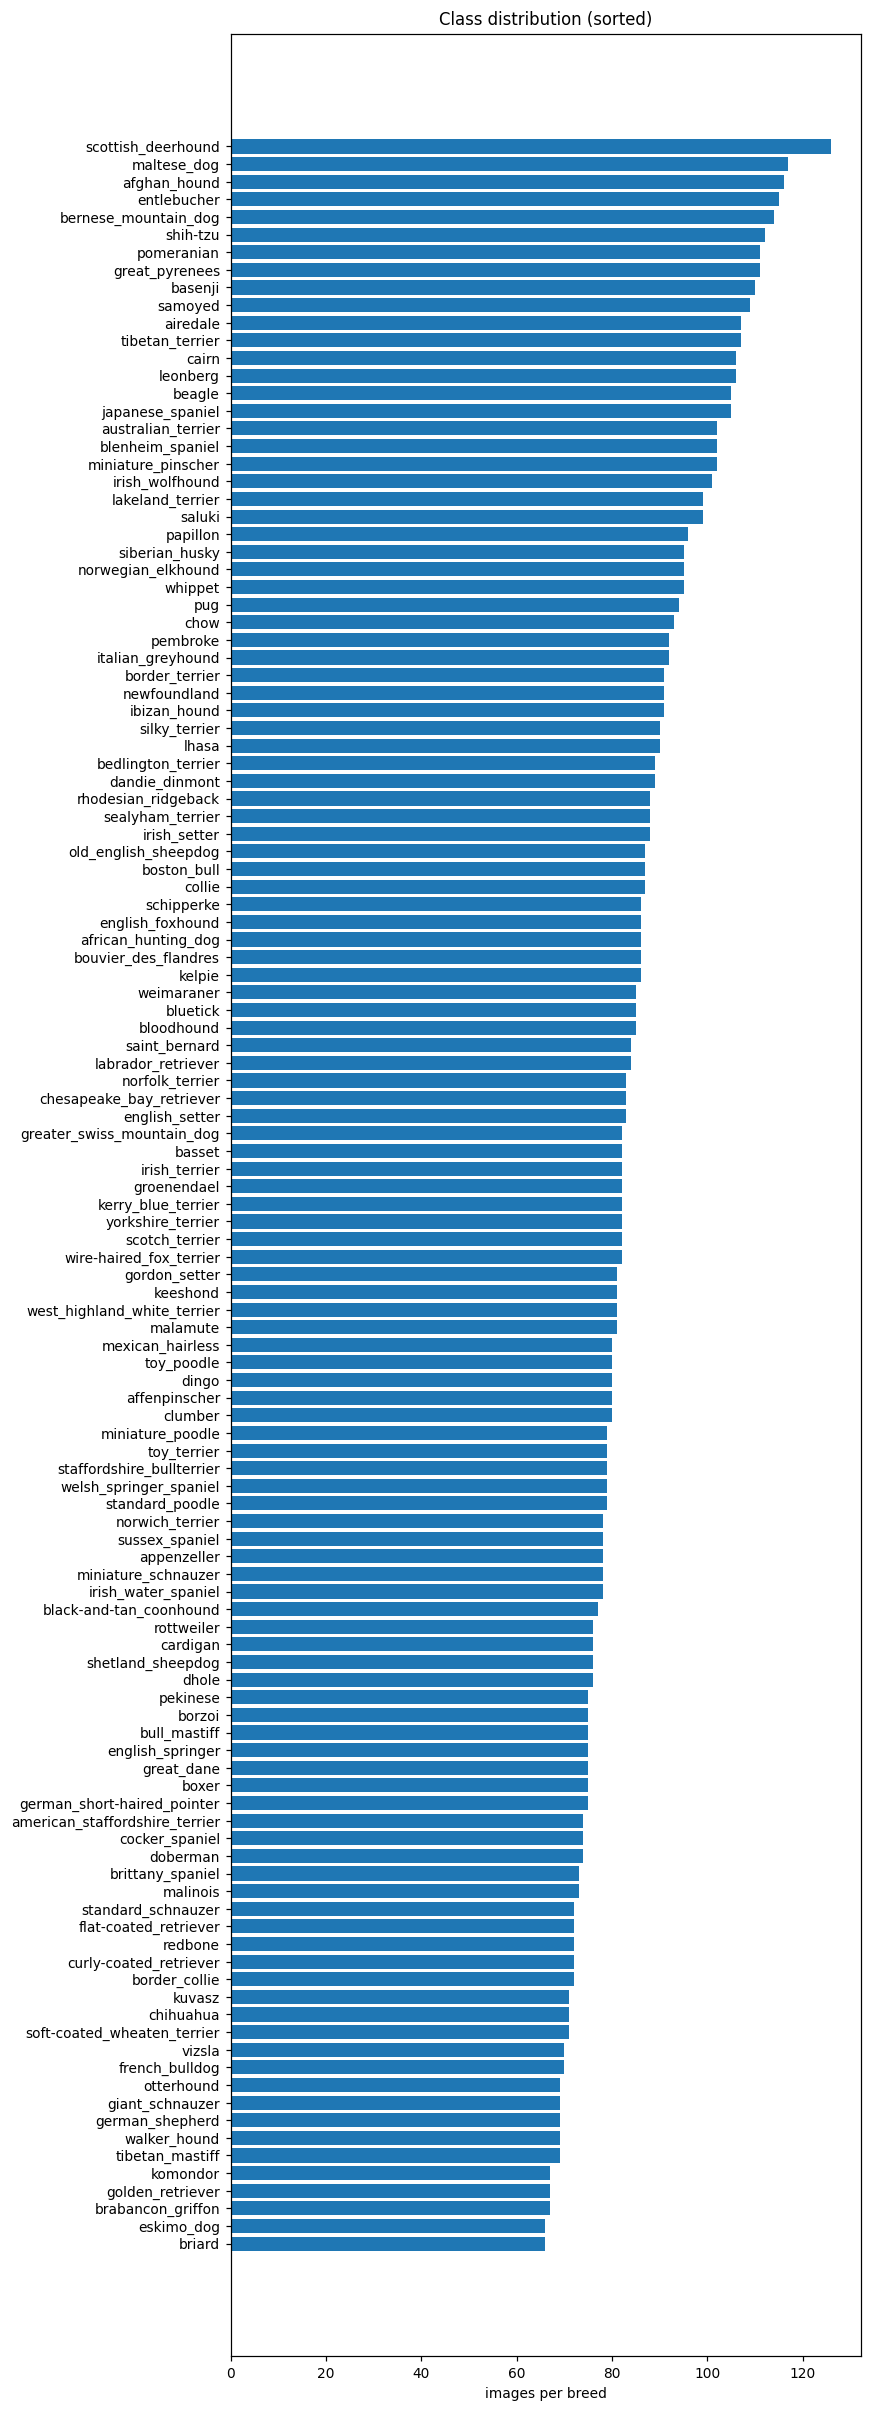


  Class distribution
  min / class                      66
  max / class                      126
  median / class                   82.0000
  imbalance ratio                  1.9091


In [8]:
# 0.2 — Class distribution.
counts = df['breed'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 22))
ax.barh(counts.index, counts.values)
ax.set_xlabel('images per breed'); ax.set_title('Class distribution (sorted)')
plt.tight_layout(); savefig('class_distribution.png'); plt.show()

section('Class distribution')
kv('min / class',     int(counts.min()))
kv('max / class',     int(counts.max()))
kv('median / class',  float(counts.median()))
kv('imbalance ratio', float(counts.max() / counts.min()))

  0%|          | 0/2000 [00:00<?, ?it/s]

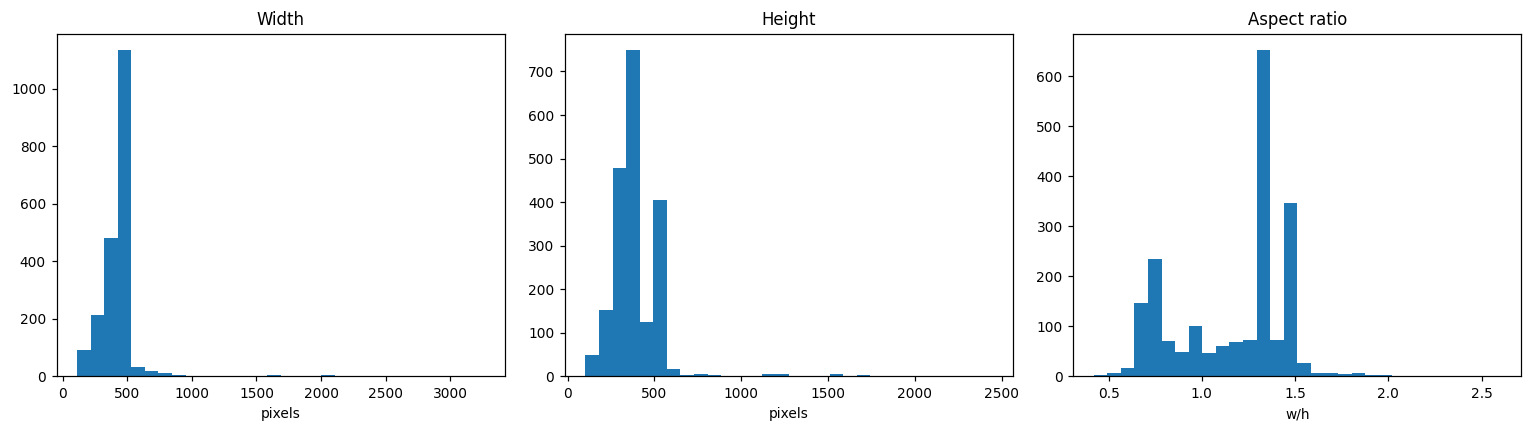


  Image properties (n=2000)
              w         h    aspect
count 2000.0000 2000.0000 2000.0000
mean   444.3000  390.0000    1.2000
std    174.6000  147.1000    0.3000
min    111.0000  103.0000    0.4000
25%    360.0000  333.0000    0.9000
50%    500.0000  375.0000    1.3000
75%    500.0000  461.5000    1.3000
max   3264.0000 2448.0000    2.6000
  image modes                      {'RGB': 2000}


In [9]:
# 0.3 — Image property distributions (random sample of 2000 for speed).
sample = df.sample(2000, random_state=SEED)
rec = []
for _id in tqdm(sample['id']):
    with Image.open(TRAIN_DIR / f'{_id}.jpg') as im:
        rec.append({'w': im.width, 'h': im.height, 'aspect': im.width / im.height, 'mode': im.mode})
prop_df = pd.DataFrame(rec)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(prop_df['w'], bins=30);      axes[0].set_title('Width');
axes[1].hist(prop_df['h'], bins=30);      axes[1].set_title('Height');
axes[2].hist(prop_df['aspect'], bins=30); axes[2].set_title('Aspect ratio');
for a in axes: a.set_xlabel('pixels' if a is not axes[2] else 'w/h')
plt.tight_layout(); savefig('image_properties.png'); plt.show()

section('Image properties (n=2000)')
print(prop_df.describe()[['w', 'h', 'aspect']].round(1))
kv('image modes', dict(Counter(prop_df['mode'])))

In [10]:
# 0.4 — Random sample grid: 10 random breeds × 4 images each.
rng = np.random.default_rng(SEED)
sample_breeds = rng.choice(breeds, size=10, replace=False)
fig, axes = plt.subplots(10, 4, figsize=(11, 26))
for i, b in enumerate(sample_breeds):
    ids = df[df['breed'] == b].sample(4, random_state=SEED)['id'].tolist()
    for j, _id in enumerate(ids):
        ax = axes[i, j]
        ax.imshow(Image.open(TRAIN_DIR / f'{_id}.jpg')); ax.axis('off')
        if j == 0: ax.set_title(b, loc='left', fontsize=10)
plt.tight_layout(); savefig('random_samples.png'); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [11]:
# 0.5 — Look-alike pairs. Hard-coded; modify if you want different pairs.
LOOKALIKE_PAIRS = [
    ('siberian_husky',  'malamute'),
    ('great_pyrenees',  'kuvasz'),
    ('whippet',         'italian_greyhound'),
    ('eskimo_dog',      'siberian_husky'),
    ('briard',          'bouvier_des_flandres'),
]
fig, axes = plt.subplots(len(LOOKALIKE_PAIRS), 6, figsize=(15, 3 * len(LOOKALIKE_PAIRS)))
for i, (b1, b2) in enumerate(LOOKALIKE_PAIRS):
    for j, b in enumerate([b1, b2]):
        ids = df[df['breed'] == b].sample(3, random_state=SEED)['id'].tolist()
        for k, _id in enumerate(ids):
            ax = axes[i, j * 3 + k]
            ax.imshow(Image.open(TRAIN_DIR / f'{_id}.jpg')); ax.axis('off')
            if k == 0: ax.set_title(b, fontsize=10)
plt.tight_layout(); savefig('lookalike_pairs.png'); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [12]:
# 0.6 — Background sample (6×5 = 30 images). No manual tagging — purely qualitative.
# Default: 30 random IDs. Override BACKGROUND_SAMPLE_IDS with your own list to inspect specific images.
BACKGROUND_SAMPLE_IDS = df.sample(30, random_state=SEED)['id'].tolist()

fig, axes = plt.subplots(5, 6, figsize=(18, 14))
for ax, _id in zip(axes.flat, BACKGROUND_SAMPLE_IDS):
    breed = df.loc[df['id'] == _id, 'breed'].item()
    ax.imshow(Image.open(TRAIN_DIR / f'{_id}.jpg')); ax.axis('off')
    ax.set_title(breed, fontsize=9)
plt.tight_layout(); savefig('background_sample.png'); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [13]:
# 0.7 — Per-channel mean / std on a 1000-image sample. Compare to ImageNet stats.
sample = df.sample(1000, random_state=SEED)
sums  = np.zeros(3, dtype=np.float64)
sqsum = np.zeros(3, dtype=np.float64)
n_pix = 0
for _id in tqdm(sample['id']):
    arr = np.asarray(Image.open(TRAIN_DIR / f'{_id}.jpg').convert('RGB'), dtype=np.float32) / 255.0
    flat = arr.reshape(-1, 3)
    sums  += flat.sum(axis=0)
    sqsum += (flat ** 2).sum(axis=0)
    n_pix += flat.shape[0]
mean = sums / n_pix
std  = np.sqrt(sqsum / n_pix - mean ** 2)

section('Per-channel statistics')
kv('dataset RGB mean', mean.round(3).tolist())
kv('dataset RGB std',  std.round(3).tolist())
kv('imagenet mean',    list(IMAGENET_MEAN))
kv('imagenet std',     list(IMAGENET_STD))

  0%|          | 0/1000 [00:00<?, ?it/s]


  Per-channel statistics
  dataset RGB mean                 [0.474, 0.451, 0.394]
  dataset RGB std                  [0.268, 0.262, 0.266]
  imagenet mean                    [0.485, 0.456, 0.406]
  imagenet std                     [0.229, 0.224, 0.225]


In [14]:
# 0.8 — Corrupt / non-RGB scan over the full dataset.
broken, modes = [], Counter()
for _id in tqdm(df['id']):
    try:
        with Image.open(TRAIN_DIR / f'{_id}.jpg') as im:
            im.load(); modes[im.mode] += 1
    except Exception as e:
        broken.append((_id, str(e)))

section('File integrity')
kv('broken files', len(broken))
kv('modes',        dict(modes))
if broken: print('first 5 broken:', broken[:5])

  0%|          | 0/10222 [00:00<?, ?it/s]


  File integrity
  broken files                     0
  modes                            {'RGB': 10222}


In [15]:
# 0.9 — Stratified 60 / 20 / 20 split. Saved to disk so every later experiment uses the same split.
if SPLITS_PATH.exists():
    splits = json.loads(SPLITS_PATH.read_text())
else:
    train_df, temp_df = train_test_split(df, test_size=0.40, stratify=df['class_idx'], random_state=SEED)
    val_df,   test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['class_idx'], random_state=SEED)
    splits = {
        'train': train_df['id'].tolist(),
        'val':   val_df['id'].tolist(),
        'test':  test_df['id'].tolist(),
    }
    SPLITS_PATH.write_text(json.dumps(splits))

section('Splits (stratified 60 / 20 / 20)')
for k, v in splits.items():
    kv(f'{k} size', len(v))
    kv(f'{k} per-class avg', len(v) / NUM_CLASSES)


  Splits (stratified 60 / 20 / 20)
  train size                       6133
  train per-class avg              51.1083
  val size                         2044
  val per-class avg                17.0333
  test size                        2045
  test per-class avg               17.0417


## Section 2 — Detector + Crops (Phase 2, Grounding-DINO)

In [23]:
# Load Grounding-DINO. Prompt is breed-agnostic on purpose (would leak labels otherwise).
# fp16 weights => ~2x faster inference + half the GPU memory, no quality hit for detection.
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

DETECTOR_ID = 'IDEA-Research/grounding-dino-base'
PROMPT = 'a dog .'
BOX_THRESHOLD = 0.30
TEXT_THRESHOLD = 0.25
MARGIN = 0.10

processor = AutoProcessor.from_pretrained(DETECTOR_ID)
detector  = AutoModelForZeroShotObjectDetection.from_pretrained(
    DETECTOR_ID, torch_dtype=torch.float16,
).to(DEVICE).eval()

section('Detector')
kv('model',           DETECTOR_ID)
kv('dtype',           'float16')
kv('prompt',          PROMPT)
kv('box threshold',   BOX_THRESHOLD)
kv('text threshold',  TEXT_THRESHOLD)
kv('margin',          MARGIN)

Loading weights:   0%|          | 0/1206 [00:00<?, ?it/s]


  Detector
  model                            IDEA-Research/grounding-dino-base
  dtype                            float16
  prompt                           a dog .
  box threshold                    0.3000
  text threshold                   0.2500
  margin                           0.1000


In [24]:
@torch.no_grad()
def detect_and_crop(image: Image.Image):
    """Return (cropped_image, used_fallback). Fallback = full image if no box passes threshold.
    Single-image API kept for ad-hoc use; the bulk loop in the next cell uses a batched path."""
    inputs = processor(images=image, text=PROMPT, return_tensors='pt').to(DEVICE)
    with torch.autocast(device_type='cuda', dtype=torch.float16):
        outputs = detector(**inputs)
    results = processor.post_process_grounded_object_detection(
        outputs, inputs.input_ids,
        threshold=BOX_THRESHOLD, text_threshold=TEXT_THRESHOLD,
        target_sizes=[image.size[::-1]],
    )[0]
    if len(results['scores']) == 0:
        return image, True
    best = int(results['scores'].argmax())
    x1, y1, x2, y2 = results['boxes'][best].cpu().numpy().tolist()
    w, h = x2 - x1, y2 - y1
    x1 = max(0, x1 - MARGIN * w); y1 = max(0, y1 - MARGIN * h)
    x2 = min(image.size[0], x2 + MARGIN * w); y2 = min(image.size[1], y2 + MARGIN * h)
    return image.crop((x1, y1, x2, y2)), False

In [26]:
# Run detector over all images. BATCHED + parallel I/O.
#
# What changed vs. the serial version:
#  - DataLoader with NUM_WORKERS background processes loads & decodes JPEGs in parallel.
#  - Grounding-DINO runs on batches of DETECT_BS images at once on the GPU (fp16).
#  - Crops are saved in a thread pool (PIL save releases the GIL during JPEG encode).
#  - Idempotent: pre-filters out IDs that already have a crop on disk.
#
# Tune DETECT_BS upward (16, 32) if GPU memory allows; downward if you OOM.

DETECT_BS = 16
DETECT_WORKERS = 2
PREFETCH = 2
NUM_WORKERS = 4

from torch.utils.data import Dataset as _Dataset, DataLoader as _DataLoader
from concurrent.futures import ThreadPoolExecutor

class _DetectDataset(_Dataset):
    """Returns (id, PIL image) pairs. We don't transform here — the HF processor does it."""
    def __init__(self, ids, image_dir):
        self.ids = ids
        self.image_dir = Path(image_dir)
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        _id = self.ids[i]
        im = Image.open(self.image_dir / f'{_id}.jpg').convert('RGB')
        im.load()  # force decode in worker, not in main process
        return _id, im

def _collate_keep(batch):
    # PIL Images can't be default-collated; just keep them as a list.
    ids   = [b[0] for b in batch]
    imgs  = [b[1] for b in batch]
    return ids, imgs

# Skip already-done IDs.
todo_ids = [_id for _id in df['id'].tolist() if not (CROP_DIR / f'{_id}.jpg').exists()]
section('Detect & crop — batched')
kv('total images',      len(df))
kv('to process',        len(todo_ids))
kv('detector batch sz', DETECT_BS)
kv('loader workers',    DETECT_WORKERS)

fallbacks = []

if todo_ids:
    ds = _DetectDataset(todo_ids, TRAIN_DIR)
    loader = _DataLoader(
        ds, batch_size=DETECT_BS, shuffle=False,
        num_workers=DETECT_WORKERS, pin_memory=False,  # PIL images, not tensors
        collate_fn=_collate_keep, prefetch_factor=PREFETCH if DETECT_WORKERS > 0 else None,
        persistent_workers=DETECT_WORKERS > 0,
    )

    save_pool = ThreadPoolExecutor(max_workers=NUM_WORKERS)
    save_futures = []

    def _crop_and_save(_id, image, box_or_none):
        """Apply the margin, crop, save. Runs in a thread."""
        if box_or_none is None:
            crop = image
        else:
            x1, y1, x2, y2 = box_or_none
            w, h = x2 - x1, y2 - y1
            x1 = max(0, x1 - MARGIN * w); y1 = max(0, y1 - MARGIN * h)
            x2 = min(image.size[0], x2 + MARGIN * w); y2 = min(image.size[1], y2 + MARGIN * h)
            crop = image.crop((x1, y1, x2, y2))
        crop.save(CROP_DIR / f'{_id}.jpg', quality=92)

    with torch.no_grad():
        for ids, imgs in tqdm(loader, total=len(loader)):
            inputs = processor(images=imgs, text=[PROMPT] * len(imgs), return_tensors='pt').to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                outputs = detector(**inputs)
            target_sizes = [im.size[::-1] for im in imgs]
            results = processor.post_process_grounded_object_detection(
                outputs, inputs.input_ids,
                threshold=BOX_THRESHOLD, text_threshold=TEXT_THRESHOLD,
                target_sizes=target_sizes,
            )

            for _id, im, res in zip(ids, imgs, results):
                if len(res['scores']) == 0:
                    fallbacks.append(_id)
                    save_futures.append(save_pool.submit(_crop_and_save, _id, im, None))
                else:
                    best = int(res['scores'].argmax())
                    box = res['boxes'][best].detach().cpu().numpy().tolist()
                    save_futures.append(save_pool.submit(_crop_and_save, _id, im, box))

    # Drain the save queue.
    for fut in tqdm(save_futures, desc='flushing saves'):
        fut.result()
    save_pool.shutdown(wait=True)

# Merge with any prior fallback list (re-runs append-safely).
fb_path = ART_DIR / 'detector_fallbacks.json'
prior = json.loads(fb_path.read_text()) if fb_path.exists() else []
all_fb = sorted(set(prior) | set(fallbacks))
fb_path.write_text(json.dumps(all_fb))

section('Detector — fallbacks')
kv('new fallbacks this run', len(fallbacks))
kv('total fallbacks',        len(all_fb))
kv('fallback rate',          len(all_fb) / max(1, len(df)))



  Detect & crop — batched
  total images                     10222
  to process                       9152
  detector batch sz                16
  loader workers                   2


  0%|          | 0/572 [00:00<?, ?it/s]

flushing saves:   0%|          | 0/9152 [00:00<?, ?it/s]


  Detector — fallbacks
  new fallbacks this run           5
  total fallbacks                  5
  fallback rate                    0.0005


In [31]:
# Sanity-check: 50 random crops in a 10×5 grid.
sanity_ids = df.sample(50, random_state=SEED)['id'].tolist()
fig, axes = plt.subplots(10, 5, figsize=(14, 28))
for ax, _id in zip(axes.flat, sanity_ids):
    breed = df.loc[df['id'] == _id, 'breed'].item()
    ax.imshow(Image.open(CROP_DIR / f'{_id}.jpg')); ax.axis('off')
    ax.set_title(breed, fontsize=8)
plt.tight_layout(); savefig('crop_sanity.png'); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [35]:
free_memory('detector', 'processor')

## Section 3 — Datasets and DataLoaders (Phase 3)

Augmentation policy is locked by the table in `keypoint.md` (Q5). We use timm's `create_transform` so the recipe stays consistent across runs.

In [36]:
def build_transforms(img_size: int, train: bool):
    if train:
        return create_transform(
            input_size=img_size,
            is_training=True,
            auto_augment='rand-m7-mstd0.5-inc1',
            interpolation='bicubic',
            re_prob=0.25, re_mode='pixel', re_count=1,
            color_jitter=0.3,
            mean=IMAGENET_MEAN, std=IMAGENET_STD,
        )
    return create_transform(
        input_size=img_size,
        is_training=False,
        interpolation='bicubic',
        crop_pct=0.95,
        mean=IMAGENET_MEAN, std=IMAGENET_STD,
    )

class DogDataset(Dataset):
    def __init__(self, df_subset, image_dir, transform):
        self.df = df_subset.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        im = Image.open(self.image_dir / f"{row['id']}.jpg").convert('RGB')
        return self.transform(im), int(row['class_idx'])

def make_loaders(image_dir, img_size, batch_size, num_workers=None):
    """Build train/val/test loaders. num_workers defaults to NUM_WORKERS from setup.

    persistent_workers=True keeps worker processes alive across epochs (saves a few s/epoch).
    prefetch_factor=PREFETCH means each worker pre-loads PREFETCH batches ahead of the GPU.
    """
    if num_workers is None:
        num_workers = NUM_WORKERS
    train_df = df[df['id'].isin(splits['train'])]
    val_df   = df[df['id'].isin(splits['val'])]
    test_df  = df[df['id'].isin(splits['test'])]
    train_ds = DogDataset(train_df, image_dir, build_transforms(img_size, train=True))
    val_ds   = DogDataset(val_df,   image_dir, build_transforms(img_size, train=False))
    test_ds  = DogDataset(test_df,  image_dir, build_transforms(img_size, train=False))

    common = dict(
        num_workers=num_workers,
        pin_memory=True,
        persistent_workers=num_workers > 0,
        prefetch_factor=PREFETCH if num_workers > 0 else None,
    )
    return (
        DataLoader(train_ds, batch_size=batch_size, shuffle=True,  drop_last=True, **common),
        DataLoader(val_ds,   batch_size=batch_size, shuffle=False, **common),
        DataLoader(test_ds,  batch_size=batch_size, shuffle=False, **common),
    )

In [ ]:
def build_transforms(img_size: int, train: bool):
    if train:
        return create_transform(
            input_size=img_size,
            is_training=True,
            auto_augment='rand-m7-mstd0.5-inc1',
            interpolation='bicubic',
            re_prob=0.25, re_mode='pixel', re_count=1,
            color_jitter=0.3,
            mean=IMAGENET_MEAN, std=IMAGENET_STD,
        )
    return create_transform(
        input_size=img_size,
        is_training=False,
        interpolation='bicubic',
        crop_pct=0.95,
        mean=IMAGENET_MEAN, std=IMAGENET_STD,
    )

class DogDataset(Dataset):
    def __init__(self, df_subset, image_dir, transform):
        self.df = df_subset.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        im = Image.open(self.image_dir / f"{row['id']}.jpg").convert('RGB')
        return self.transform(im), int(row['class_idx'])

def make_loaders(image_dir, img_size, batch_size, num_workers=4):
    train_df = df[df['id'].isin(splits['train'])]
    val_df   = df[df['id'].isin(splits['val'])]
    test_df  = df[df['id'].isin(splits['test'])]
    train_ds = DogDataset(train_df, image_dir, build_transforms(img_size, train=True))
    val_ds   = DogDataset(val_df,   image_dir, build_transforms(img_size, train=False))
    test_ds  = DogDataset(test_df,  image_dir, build_transforms(img_size, train=False))
    return (
        DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=True, drop_last=True),
        DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True),
        DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True),
    )

## Section 4 — Training Utilities

Single `train_one(...)` function used by E0–E3 with different arguments. MixUp / CutMix and label-smoothing are wired through `timm.data.Mixup` + `SoftTargetCrossEntropy`.

In [37]:
mixup = Mixup(
    mixup_alpha=0.2, cutmix_alpha=1.0, prob=0.5, switch_prob=0.5,
    label_smoothing=0.1, num_classes=NUM_CLASSES,
)
soft_ce   = SoftTargetCrossEntropy()
ce_smooth = nn.CrossEntropyLoss(label_smoothing=0.1)

In [38]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    logits_all, ys_all = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
            logits = model(x).float()
        logits_all.append(logits.cpu()); ys_all.append(y)
    logits = torch.cat(logits_all); ys = torch.cat(ys_all)
    probs = logits.softmax(dim=1)
    ll   = nn.functional.nll_loss(probs.clamp_min(1e-12).log(), ys).item()
    top1 = (probs.argmax(1) == ys).float().mean().item()
    top5 = (probs.topk(5, dim=1).indices == ys.unsqueeze(1)).any(dim=1).float().mean().item()
    return ll, top1, top5, probs.numpy(), ys.numpy()

@torch.no_grad()
def predict_probs(model, loader, tta=False):
    model.eval()
    probs_all, ys_all = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
            logits = model(x).float()
            if tta:
                logits = (logits + model(x.flip(dims=[3])).float()) / 2
        probs_all.append(logits.softmax(dim=1).cpu()); ys_all.append(y)
    return torch.cat(probs_all).numpy(), torch.cat(ys_all).numpy()

In [39]:
def train_one(model, train_loader, val_loader,
              epochs, base_lr, head_lr=None, wd=0.05,
              freeze_backbone=False, use_mixup=True, run_name='run'):
    """Generic training loop used by E0-E3. Returns the history DataFrame.
    Saves the best checkpoint by val log-loss to ART_DIR/{run_name}.pt."""
    model = model.to(DEVICE)
    head_lr = head_lr if head_lr is not None else base_lr

    head = model.get_classifier()
    head_param_ids = {id(p) for p in head.parameters()}
    if freeze_backbone:
        for p in model.parameters(): p.requires_grad = False
        for p in head.parameters(): p.requires_grad = True
        param_groups = [{'params': head.parameters(), 'lr': head_lr}]
    else:
        backbone_params = [p for p in model.parameters() if id(p) not in head_param_ids]
        param_groups = [
            {'params': backbone_params, 'lr': base_lr},
            {'params': head.parameters(), 'lr': head_lr},
        ]
    optimizer = optim.AdamW(param_groups, weight_decay=wd)
    total_steps = len(train_loader) * epochs
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=[g['lr'] for g in optimizer.param_groups],
        total_steps=total_steps, pct_start=0.10,
    )

    section(f'Training {run_name}')
    kv('epochs', epochs); kv('base_lr', base_lr); kv('head_lr', head_lr); kv('wd', wd)
    kv('freeze_backbone', freeze_backbone); kv('mixup', use_mixup)
    kv('train batches', len(train_loader)); kv('val batches', len(val_loader))

    history, best_ll = [], float('inf')
    for ep in range(1, epochs + 1):
        # Backbone in eval() (frozen BN) when not fine-tuning; head is just Linear.
        if freeze_backbone: model.eval()
        else:               model.train()

        running_loss, n_seen = 0.0, 0
        for x, y in train_loader:
            x = x.to(DEVICE, non_blocking=True); y = y.to(DEVICE, non_blocking=True)
            if use_mixup:
                x_mix, y_mix = mixup(x, y); loss_fn = soft_ce; target = y_mix
            else:
                x_mix, target = x, y; loss_fn = ce_smooth

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
                logits = model(x_mix)
                loss = loss_fn(logits, target)
            loss.backward()
            optimizer.step(); scheduler.step()

            running_loss += loss.item() * x.size(0); n_seen += x.size(0)
        train_loss = running_loss / n_seen

        val_ll, val_top1, val_top5, _, _ = evaluate(model, val_loader)
        history.append({'epoch': ep, 'train_loss': train_loss,
                        'val_ll': val_ll, 'val_top1': val_top1, 'val_top5': val_top5})
        print(f'  ep {ep:02d} | train {train_loss:.4f} | val_ll {val_ll:.4f} | top1 {val_top1:.4f} | top5 {val_top5:.4f}')
        if val_ll < best_ll:
            best_ll = val_ll
            torch.save(model.state_dict(), ART_DIR / f'{run_name}.pt')

    hist_df = pd.DataFrame(history)
    hist_df.to_csv(ART_DIR / f'history_{run_name}.csv', index=False)
    kv('best val_ll', best_ll)
    return hist_df

## Section 5 — Hyperparameter Sweep (Phase 4a)

Cheap sweep on the ResNet-50 baseline at 224. Picks LR / WD that lock in for E1. Five short runs of 5 epochs each.

In [44]:
# 0.9 — Stratified 60 / 20 / 20 split. Saved to disk so every later experiment uses the same split.
if SPLITS_PATH.exists():
    splits = json.loads(SPLITS_PATH.read_text())
else:
  print('check the dictionary?')


section('Splits (stratified 60 / 20 / 20)')
for k, v in splits.items():
    kv(f'{k} size', len(v))
    kv(f'{k} per-class avg', len(v) / NUM_CLASSES)


  Splits (stratified 60 / 20 / 20)
  train size                       6133
  train per-class avg              51.1083
  val size                         2044
  val per-class avg                17.0333
  test size                        2045
  test per-class avg               17.0417


In [45]:
SWEEP = [
    {'base_lr': 1e-5, 'head_lr': 1e-4, 'wd': 0.05},
    {'base_lr': 3e-5, 'head_lr': 3e-4, 'wd': 0.05},
    {'base_lr': 3e-5, 'head_lr': 3e-4, 'wd': 0.01},
    {'base_lr': 1e-4, 'head_lr': 1e-3, 'wd': 0.05},
    {'base_lr': 1e-4, 'head_lr': 1e-3, 'wd': 0.01},
]

tl, vl, _ = make_loaders(TRAIN_DIR, img_size=224, batch_size=128)
sweep_rows = []
for cfg in SWEEP:
    torch.manual_seed(SEED)
    m = timm.create_model('resnet50', pretrained=True, num_classes=NUM_CLASSES)
    name = f"sweep_{cfg['base_lr']:.0e}_{cfg['head_lr']:.0e}_{cfg['wd']}"
    h = train_one(m, tl, vl, epochs=5, run_name=name, **cfg)
    best = h['val_ll'].min()
    sweep_rows.append({**cfg, 'best_val_ll': best})

sweep_df = pd.DataFrame(sweep_rows).sort_values('best_val_ll')
sweep_df.to_csv(ART_DIR / 'sweep.csv', index=False)
section('HP sweep (ResNet-50 @ 224, 5 epochs)')
print(sweep_df)
BEST_HP = sweep_df.iloc[0][['base_lr', 'head_lr', 'wd']].to_dict()
kv('locked-in HP', BEST_HP)

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]


  Training sweep_1e-05_1e-04_0.05
  epochs                           5
  base_lr                          0.0000
  head_lr                          0.0001
  wd                               0.0500
  freeze_backbone                  False
  mixup                            True
  train batches                    47
  val batches                      16
  ep 01 | train 4.7693 | val_ll 4.6987 | top1 0.0797 | top5 0.2573
  ep 02 | train 4.6906 | val_ll 4.5703 | top1 0.2578 | top5 0.5553
  ep 03 | train 4.6307 | val_ll 4.5139 | top1 0.3743 | top5 0.7050
  ep 04 | train 4.5873 | val_ll 4.4601 | top1 0.4227 | top5 0.7593
  ep 05 | train 4.5828 | val_ll 4.4636 | top1 0.4286 | top5 0.7617
  best val_ll                      4.4601

  Training sweep_3e-05_3e-04_0.05
  epochs                           5
  base_lr                          0.0000
  head_lr                          0.0003
  wd                               0.0500
  freeze_backbone                  False
  mixup                      

/usr/local/lib/python3.12/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:91: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


  ep 02 | train 4.4997 | val_ll 4.1297 | top1 0.6981 | top5 0.9335


/usr/local/lib/python3.12/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:91: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


  ep 03 | train 4.1775 | val_ll 3.4463 | top1 0.7539 | top5 0.9545
  ep 04 | train 4.0344 | val_ll 3.4853 | top1 0.8028 | top5 0.9721
  ep 05 | train 3.9501 | val_ll 3.3770 | top1 0.7994 | top5 0.9726
  best val_ll                      3.3770

  Training sweep_3e-05_3e-04_0.01
  epochs                           5
  base_lr                          0.0000
  head_lr                          0.0003
  wd                               0.0100
  freeze_backbone                  False
  mixup                            True
  train batches                    47
  val batches                      16


... (8 outputs left out)

/usr/local/lib/python3.12/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:91: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


  ep 05 | train 2.4213 | val_ll 0.7567 | top1 0.9026 | top5 0.9873
  best val_ll                      0.6089


/usr/local/lib/python3.12/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:91: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)



  Training sweep_1e-04_1e-03_0.01
  epochs                           5
  base_lr                          0.0001
  head_lr                          0.0010
  wd                               0.0100
  freeze_backbone                  False
  mixup                            True
  train batches                    47
  val batches                      16
  ep 01 | train 4.5680 | val_ll 3.4020 | top1 0.7554 | top5 0.9511
  ep 02 | train 3.4446 | val_ll 1.1509 | top1 0.8801 | top5 0.9848
  ep 03 | train 2.5546 | val_ll 0.7779 | top1 0.8943 | top5 0.9873
  ep 04 | train 2.2472 | val_ll 0.6881 | top1 0.9031 | top5 0.9883
  ep 05 | train 2.3023 | val_ll 0.7298 | top1 0.9041 | top5 0.9883
  best val_ll                      0.6881

  HP sweep (ResNet-50 @ 224, 5 epochs)
   base_lr  head_lr     wd  best_val_ll
3   0.0001   0.0010 0.0500       0.6089
4   0.0001   0.0010 0.0100       0.6881
2   0.0000   0.0003 0.0100       3.2987
1   0.0000   0.0003 0.0500       3.3770
0   0.0000   0.0001 0.0500  

## Section 6 — Experiment E0: ResNet-50 frozen + linear head

*Question:* what does ImageNet alone give us, with no fine-tuning?

In [46]:
torch.manual_seed(SEED)
tl, vl, _ = make_loaders(TRAIN_DIR, img_size=224, batch_size=128)
model_e0 = timm.create_model('resnet50', pretrained=True, num_classes=NUM_CLASSES)
hist_e0 = train_one(
    model_e0, tl, vl,
    epochs=10, base_lr=0.0, head_lr=1e-3, wd=0.01,
    freeze_backbone=True, use_mixup=False, run_name='E0',
)


  Training E0
  epochs                           10
  base_lr                          0.0000
  head_lr                          0.0010
  wd                               0.0100
  freeze_backbone                  True
  mixup                            False
  train batches                    47
  val batches                      16
  ep 01 | train 4.6295 | val_ll 4.0506 | top1 0.7647 | top5 0.9633
  ep 02 | train 3.7694 | val_ll 2.7951 | top1 0.8821 | top5 0.9887
  ep 03 | train 2.9680 | val_ll 1.9134 | top1 0.8953 | top5 0.9902
  ep 04 | train 2.4455 | val_ll 1.3868 | top1 0.9022 | top5 0.9912
  ep 05 | train 2.1434 | val_ll 1.1017 | top1 0.9075 | top5 0.9922
  ep 06 | train 1.9694 | val_ll 0.9484 | top1 0.9114 | top5 0.9922
  ep 07 | train 1.8819 | val_ll 0.8679 | top1 0.9114 | top5 0.9922
  ep 08 | train 1.8389 | val_ll 0.8295 | top1 0.9124 | top5 0.9922
  ep 09 | train 1.8314 | val_ll 0.8157 | top1 0.9134 | top5 0.9922
  ep 10 | train 1.8211 | val_ll 0.8137 | top1 0.9134 | top5 0

## Section 7 — Experiment E1: ResNet-50 fine-tuned

*Question:* how much does end-to-end fine-tuning add over frozen features?

In [47]:
torch.manual_seed(SEED)
tl, vl, _ = make_loaders(TRAIN_DIR, img_size=224, batch_size=128)
model_e1 = timm.create_model('resnet50', pretrained=True, num_classes=NUM_CLASSES)
hist_e1 = train_one(
    model_e1, tl, vl,
    epochs=20,
    base_lr=BEST_HP['base_lr'], head_lr=BEST_HP['head_lr'], wd=BEST_HP['wd'],
    use_mixup=True, run_name='E1',
)


  Training E1
  epochs                           20
  base_lr                          0.0001
  head_lr                          0.0010
  wd                               0.0500
  freeze_backbone                  False
  mixup                            True
  train batches                    47
  val batches                      16
  ep 01 | train 4.7506 | val_ll 4.5720 | top1 0.2828 | top5 0.5895
  ep 02 | train 4.2654 | val_ll 2.5581 | top1 0.8043 | top5 0.9711
  ep 03 | train 3.0005 | val_ll 0.7791 | top1 0.8904 | top5 0.9892
  ep 04 | train 2.3291 | val_ll 0.6054 | top1 0.8929 | top5 0.9887
  ep 05 | train 2.2987 | val_ll 0.6698 | top1 0.8982 | top5 0.9892
  ep 06 | train 2.2003 | val_ll 0.5789 | top1 0.9041 | top5 0.9912
  ep 07 | train 1.9394 | val_ll 0.4767 | top1 0.9051 | top5 0.9892
  ep 08 | train 1.9498 | val_ll 0.5331 | top1 0.9070 | top5 0.9897
  ep 09 | train 1.9922 | val_ll 0.4747 | top1 0.9056 | top5 0.9897
  ep 10 | train 1.8880 | val_ll 0.4896 | top1 0.9105 | top5 0

In [48]:
free_memory('model_e0', 'model_e1')

## Section 8 — Experiment E2: ConvNeXt-Base @ 384, full image

*Question:* how much does a stronger backbone + higher resolution add?

In [49]:
torch.manual_seed(SEED)
tl, vl, _ = make_loaders(TRAIN_DIR, img_size=384, batch_size=32)
model_e2 = timm.create_model('convnext_base.fb_in22k_ft_in1k_384',
                             pretrained=True, num_classes=NUM_CLASSES)
hist_e2 = train_one(
    model_e2, tl, vl,
    epochs=15, base_lr=2e-5, head_lr=2e-4, wd=0.05,
    use_mixup=True, run_name='E2',
)

model.safetensors:   0%|          | 0.00/354M [00:00<?, ?B/s]


  Training E2
  epochs                           15
  base_lr                          0.0000
  head_lr                          0.0002
  wd                               0.0500
  freeze_backbone                  False
  mixup                            True
  train batches                    191
  val batches                      64
  ep 01 | train 4.4710 | val_ll 2.5469 | top1 0.7280 | top5 0.9633
  ep 02 | train 2.2124 | val_ll 0.5312 | top1 0.9022 | top5 0.9917
  ep 03 | train 1.8432 | val_ll 0.4188 | top1 0.9070 | top5 0.9932
  ep 04 | train 1.7739 | val_ll 0.3903 | top1 0.9066 | top5 0.9917
  ep 05 | train 1.6543 | val_ll 0.3809 | top1 0.9173 | top5 0.9922
  ep 06 | train 1.6269 | val_ll 0.3747 | top1 0.9183 | top5 0.9941
  ep 07 | train 1.5812 | val_ll 0.3746 | top1 0.9159 | top5 0.9932
  ep 08 | train 1.6565 | val_ll 0.3667 | top1 0.9198 | top5 0.9936
  ep 09 | train 1.5906 | val_ll 0.3691 | top1 0.9217 | top5 0.9932
  ep 10 | train 1.5944 | val_ll 0.3705 | top1 0.9203 | top5 

In [50]:
free_memory('model_e2')

## Section 9 — Experiment E3: ConvNeXt-Base @ 384, **cropped** image (HEADLINE)

*Question:* does removing the background help on a fine-grained task? E2 vs E3 is the comparison.

In [51]:
torch.manual_seed(SEED)
tl, vl, _ = make_loaders(CROP_DIR, img_size=384, batch_size=32)
model_e3 = timm.create_model('convnext_base.fb_in22k_ft_in1k_384',
                             pretrained=True, num_classes=NUM_CLASSES)
hist_e3 = train_one(
    model_e3, tl, vl,
    epochs=15, base_lr=2e-5, head_lr=2e-4, wd=0.05,
    use_mixup=True, run_name='E3',
)


  Training E3
  epochs                           15
  base_lr                          0.0000
  head_lr                          0.0002
  wd                               0.0500
  freeze_backbone                  False
  mixup                            True
  train batches                    191
  val batches                      64
  ep 01 | train 4.4275 | val_ll 2.4755 | top1 0.7187 | top5 0.9623
  ep 02 | train 2.2482 | val_ll 0.5870 | top1 0.8850 | top5 0.9887
  ep 03 | train 1.8409 | val_ll 0.4728 | top1 0.8963 | top5 0.9892
  ep 04 | train 1.7678 | val_ll 0.4429 | top1 0.8973 | top5 0.9883
  ep 05 | train 1.6912 | val_ll 0.4352 | top1 0.9031 | top5 0.9878
  ep 06 | train 1.7312 | val_ll 0.4286 | top1 0.9036 | top5 0.9883
  ep 07 | train 1.6409 | val_ll 0.4173 | top1 0.9070 | top5 0.9887
  ep 08 | train 1.5931 | val_ll 0.4231 | top1 0.9085 | top5 0.9868
  ep 09 | train 1.6542 | val_ll 0.4272 | top1 0.9095 | top5 0.9873
  ep 10 | train 1.5995 | val_ll 0.4241 | top1 0.9051 | top5 

## Section 10 — Inference, TTA, Calibration (Phase 4d)

For each model, we (a) reload best-val checkpoint, (b) get test-set probabilities (with hflip TTA for the strong models), (c) fit a temperature on val probs and apply it to test probs.

In [52]:
def fit_temperature(val_probs, val_ys, max_iter=200):
    """Fit a single temperature scalar by minimizing val NLL via LBFGS."""
    logits = torch.tensor(np.log(np.clip(val_probs, 1e-12, 1.0)), dtype=torch.float32)
    ys     = torch.tensor(val_ys, dtype=torch.long)
    T = nn.Parameter(torch.ones(1) * 1.5)
    opt = optim.LBFGS([T], lr=0.05, max_iter=max_iter)
    def closure():
        opt.zero_grad()
        loss = nn.functional.cross_entropy(logits / T.clamp_min(1e-3), ys)
        loss.backward(); return loss
    opt.step(closure)
    return float(T.item())

def apply_temperature(probs, T):
    logits = np.log(np.clip(probs, 1e-12, 1.0)) / T
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

In [53]:
def collect_probs(run_name, image_dir, img_size, batch_size, tta=False, model_arch='resnet50'):
    """Reload the best-val checkpoint for a run and produce val + test probabilities."""
    _, vl, tl_test = make_loaders(image_dir, img_size=img_size, batch_size=batch_size)
    m = timm.create_model(model_arch, pretrained=False, num_classes=NUM_CLASSES).to(DEVICE)
    m.load_state_dict(torch.load(ART_DIR / f'{run_name}.pt', map_location=DEVICE))
    val_probs,  val_ys  = predict_probs(m, vl,      tta=tta)
    test_probs, test_ys = predict_probs(m, tl_test, tta=tta)
    np.savez(ART_DIR / f'probs_{run_name}.npz',
             val_probs=val_probs, val_ys=val_ys,
             test_probs=test_probs, test_ys=test_ys)
    return val_probs, val_ys, test_probs, test_ys

RUN_SPEC = {
    'E0': dict(image_dir=TRAIN_DIR, img_size=224, batch_size=256, tta=False, model_arch='resnet50'),
    'E1': dict(image_dir=TRAIN_DIR, img_size=224, batch_size=256, tta=True,  model_arch='resnet50'),
    'E2': dict(image_dir=TRAIN_DIR, img_size=384, batch_size=64,  tta=True,  model_arch='convnext_base.fb_in22k_ft_in1k_384'),
    'E3': dict(image_dir=CROP_DIR,  img_size=384, batch_size=64,  tta=True,  model_arch='convnext_base.fb_in22k_ft_in1k_384'),
}

PROBS = {}
TEMPS = {}
for name, spec in RUN_SPEC.items():
    vp, vy, tp, ty = collect_probs(name, **spec)
    T = fit_temperature(vp, vy)
    tp_cal = apply_temperature(tp, T)
    PROBS[name] = {'val_probs': vp, 'val_ys': vy,
                   'test_probs': tp, 'test_probs_cal': tp_cal, 'test_ys': ty}
    TEMPS[name] = T
    section(f'{name} — temperature scaling')
    kv('T*', T)


  E0 — temperature scaling
  T*                               -0.7012

  E1 — temperature scaling
  T*                               0.6189

  E2 — temperature scaling
  T*                               0.7154

  E3 — temperature scaling
  T*                               0.7178


## Section 11 — Performance Analysis (Phase 5)

Headline table → per-class crop benefit → confusion matrix → calibration.

In [54]:
def compute_ece(probs, ys, n_bins=15):
    confs = probs.max(axis=1)
    preds = probs.argmax(axis=1)
    correct = (preds == ys).astype(np.float64)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (confs >= bins[i]) & (confs < bins[i + 1] if i < n_bins - 1 else confs <= bins[i + 1])
        if m.sum() > 0:
            ece += abs(confs[m].mean() - correct[m].mean()) * (m.sum() / len(confs))
    return float(ece)

def headline_row(name, probs, ys):
    return {
        'run':       name,
        'log_loss':  log_loss(ys, probs, labels=list(range(NUM_CLASSES))),
        'top1':      accuracy_score(ys, probs.argmax(1)),
        'top5':      np.mean([ys[i] in probs[i].argsort()[-5:] for i in range(len(ys))]),
        'macro_f1':  f1_score(ys, probs.argmax(1), average='macro'),
        'ece':       compute_ece(probs, ys),
    }

rows_raw = [headline_row(n, P['test_probs'],     P['test_ys']) for n, P in PROBS.items()]
rows_cal = [headline_row(n, P['test_probs_cal'], P['test_ys']) for n, P in PROBS.items()]
head_raw = pd.DataFrame(rows_raw).set_index('run')
head_cal = pd.DataFrame(rows_cal).set_index('run')

section('Headline metrics — raw probabilities')
print(head_raw)
section('Headline metrics — temperature-scaled')
print(head_cal)
head_raw.to_csv(ART_DIR / 'headline_raw.csv')
head_cal.to_csv(ART_DIR / 'headline_cal.csv')


  Headline metrics — raw probabilities
     log_loss   top1   top5  macro_f1    ece
run                                         
E0     0.8365 0.9227 0.9936    0.9173 0.4077
E1     0.4510 0.9125 0.9892    0.9070 0.1605
E2     0.3795 0.9188 0.9936    0.9137 0.1137
E3     0.4508 0.8870 0.9917    0.8816 0.1030

  Headline metrics — temperature-scaled
     log_loss   top1   top5  macro_f1    ece
run                                         
E0    12.8976 0.0000 0.0000    0.0000 0.0432
E1     0.2897 0.9125 0.9892    0.9070 0.0116
E2     0.2868 0.9188 0.9936    0.9137 0.0176
E3     0.3605 0.8870 0.9917    0.8816 0.0235


In [55]:
# Per-class crop benefit (E2 → E3). Which breeds gain the most from removing background?
ys_test = PROBS['E2']['test_ys']
preds_e2 = PROBS['E2']['test_probs_cal'].argmax(1)
preds_e3 = PROBS['E3']['test_probs_cal'].argmax(1)

rows = []
for c in range(NUM_CLASSES):
    mask = ys_test == c
    if mask.sum() == 0: continue
    rows.append({
        'breed':    idx2breed[c],
        'n_test':   int(mask.sum()),
        'acc_E2':   float((preds_e2[mask] == c).mean()),
        'acc_E3':   float((preds_e3[mask] == c).mean()),
    })
crop_table = pd.DataFrame(rows)
crop_table['delta'] = crop_table['acc_E3'] - crop_table['acc_E2']
crop_table = crop_table.sort_values('delta', ascending=False)
crop_table.to_csv(ART_DIR / 'per_class_crop_benefit.csv', index=False)

section('Top 15 breeds gaining from crop')
print(crop_table.head(15).to_string(index=False))
section('Top 15 breeds hurt by crop')
print(crop_table.tail(15)[::-1].to_string(index=False))
section('Crop benefit summary')
kv('breeds with positive delta', int((crop_table['delta'] > 0).sum()))
kv('breeds with negative delta', int((crop_table['delta'] < 0).sum()))
kv('breeds unchanged',           int((crop_table['delta'] == 0).sum()))
kv('mean delta (acc)',           float(crop_table['delta'].mean()))


  Top 15 breeds gaining from crop
                         breed  n_test  acc_E2  acc_E3  delta
american_staffordshire_terrier      15  0.7333  1.0000 0.2667
              miniature_poodle      16  0.6250  0.8125 0.1875
                        briard      13  0.8462  1.0000 0.1538
                      cardigan      15  0.7333  0.8667 0.1333
                   appenzeller      15  0.8000  0.9333 0.1333
                 silky_terrier      18  0.7778  0.8889 0.1111
            scottish_deerhound      25  0.8400  0.9200 0.0800
              golden_retriever      13  0.9231  1.0000 0.0769
                  walker_hound      14  0.7143  0.7857 0.0714
        curly-coated_retriever      14  0.9286  1.0000 0.0714
               tibetan_mastiff      14  0.7857  0.8571 0.0714
                    great_dane      15  0.9333  1.0000 0.0667
                         boxer      15  0.8667  0.9333 0.0667
                      malamute      16  0.8750  0.9375 0.0625
                    weimaraner     

In [56]:
# Confusion-matrix analysis for E3. List the top-20 confused (true → predicted) pairs.
preds_e3 = PROBS['E3']['test_probs_cal'].argmax(1)
cm = confusion_matrix(PROBS['E3']['test_ys'], preds_e3, labels=list(range(NUM_CLASSES)))
off = cm.copy(); np.fill_diagonal(off, 0)

pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and off[i, j] > 0:
            pairs.append({'true': idx2breed[i], 'predicted': idx2breed[j], 'count': int(off[i, j])})
pair_df = pd.DataFrame(pairs).sort_values('count', ascending=False).head(20).reset_index(drop=True)
pair_df.to_csv(ART_DIR / 'top_confused_pairs_E3.csv', index=False)

section('Top-20 confused pairs (E3, true → predicted)')
print(pair_df.to_string(index=False))

# Same analysis for E2 — does cropping change which pairs are confused?
preds_e2 = PROBS['E2']['test_probs_cal'].argmax(1)
cm_e2 = confusion_matrix(PROBS['E2']['test_ys'], preds_e2, labels=list(range(NUM_CLASSES)))
off_e2 = cm_e2.copy(); np.fill_diagonal(off_e2, 0)
pairs_e2 = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and off_e2[i, j] > 0:
            pairs_e2.append({'true': idx2breed[i], 'predicted': idx2breed[j], 'count': int(off_e2[i, j])})
pair_e2_df = pd.DataFrame(pairs_e2).sort_values('count', ascending=False).head(20).reset_index(drop=True)
pair_e2_df.to_csv(ART_DIR / 'top_confused_pairs_E2.csv', index=False)

section('Top-20 confused pairs (E2, full image, true → predicted)')
print(pair_e2_df.to_string(index=False))


  Top-20 confused pairs (E3, true → predicted)
                      true                      predicted  count
                eskimo_dog                 siberian_husky     10
 staffordshire_bullterrier american_staffordshire_terrier      8
greater_swiss_mountain_dog                    appenzeller      6
            siberian_husky                       malamute      6
                    collie              shetland_sheepdog      5
          english_foxhound                   walker_hound      5
                    collie                  border_collie      5
           norwich_terrier                norfolk_terrier      4
        standard_schnauzer            miniature_schnauzer      3
           irish_wolfhound             scottish_deerhound      3
                eskimo_dog                       malamute      3
                    kelpie                          dingo      3
      bouvier_des_flandres                giant_schnauzer      3
        australian_terrier                

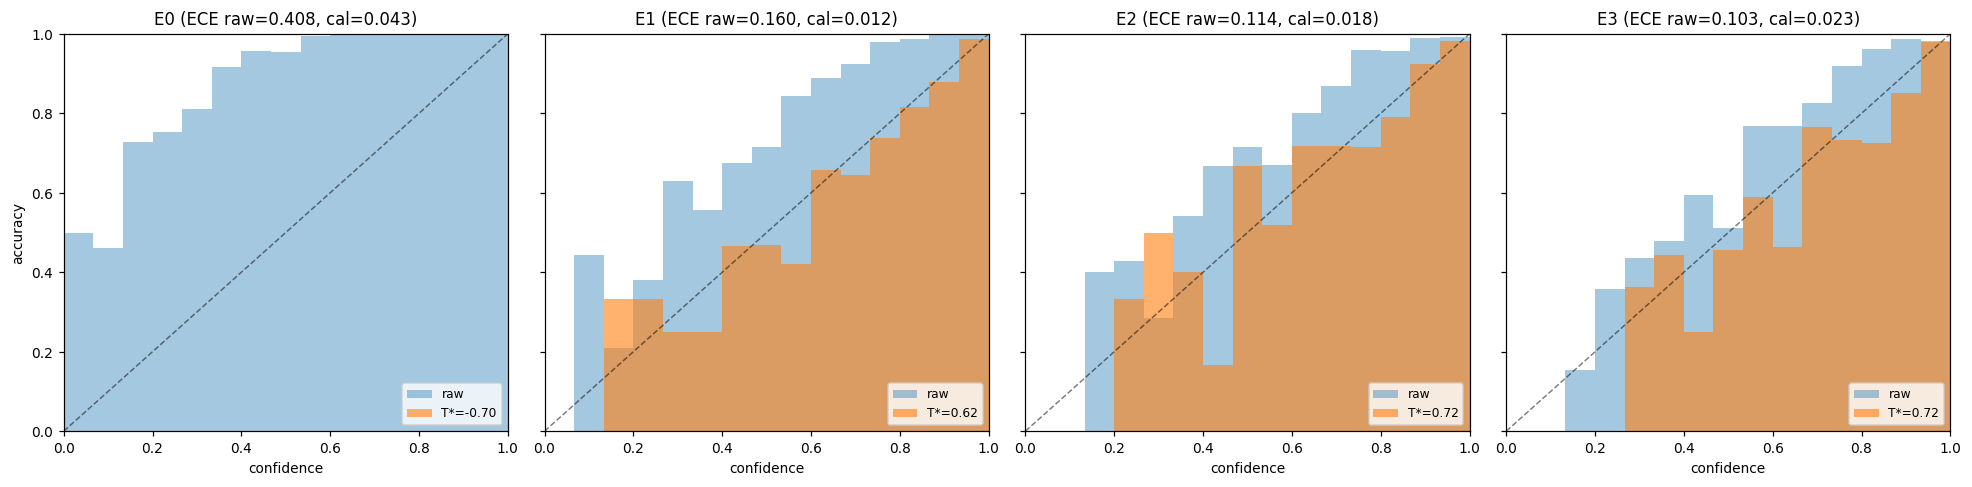

In [57]:
# Reliability diagram: confidence vs accuracy by bin, before and after temperature scaling.
def reliability(probs, ys, n_bins=15):
    confs = probs.max(axis=1); preds = probs.argmax(axis=1)
    correct = (preds == ys).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)
    centres, accs, weights = [], [], []
    for i in range(n_bins):
        m = (confs >= bins[i]) & (confs < bins[i + 1] if i < n_bins - 1 else confs <= bins[i + 1])
        if m.sum() > 0:
            centres.append(0.5 * (bins[i] + bins[i + 1]))
            accs.append(correct[m].mean())
            weights.append(m.sum() / len(confs))
    return np.array(centres), np.array(accs), np.array(weights)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, name in zip(axes, ['E0', 'E1', 'E2', 'E3']):
    P = PROBS[name]; ys = P['test_ys']
    cR, aR, wR = reliability(P['test_probs'],     ys)
    cC, aC, wC = reliability(P['test_probs_cal'], ys)
    ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
    ax.bar(cR, aR, width=1/15, alpha=0.4, label='raw')
    ax.bar(cC, aC, width=1/15, alpha=0.6, label=f'T*={TEMPS[name]:.2f}')
    ax.set_title(f"{name} (ECE raw={compute_ece(P['test_probs'], ys):.3f}, cal={compute_ece(P['test_probs_cal'], ys):.3f})")
    ax.set_xlabel('confidence'); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('accuracy')
plt.tight_layout(); savefig('reliability_diagrams.png'); plt.show()

## Artifacts


After running the notebook, the four artifacts that drive the report are:

1. `headline_cal.csv` — log-loss / top-1 / top-5 / macro-F1 / ECE for E0–E3 (after temperature scaling).
2. `per_class_crop_benefit.csv` — which breeds gained / lost from cropping; the headline finding.
3. `top_confused_pairs_E2.csv` and `top_confused_pairs_E3.csv` — does cropping change which pairs are confused?
4. `reliability_diagrams.png` — calibration before and after temperature scaling.


In [ ]:
print('finished')

## Section 13 — Report figure: per-class effect of cropping

Reproduces the single figure used in the 1–2 page write-up. 
Reads `artifacts/per_class_crop_benefit.csv` (already produced 
in Section 11) and writes `figures/perclass.pdf`. Self-contained: 
does not depend on `PROBS` being live in the kernel.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ART = Path('artifacts')
FIG = Path('figures'); FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'figure.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
})

df = pd.read_csv(ART / 'per_class_crop_benefit.csv').sort_values('delta')
n = 8                       # top-N winners and losers
losers  = df.head(n)
winners = df.tail(n).iloc[::-1]
rows = pd.concat([winners, losers]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7.0, 2.6))
colors = ['#1a9850' if d > 0 else '#d7191c' for d in rows['delta']]
y = np.arange(len(rows))
ax.barh(y, rows['delta'] * 100, color=colors)
ax.set_yticks(y)
ax.set_yticklabels([b.replace('_', ' ') for b in rows['breed']], fontsize=7)
ax.invert_yaxis()
ax.axvline(0, color='black', lw=0.6)
ax.set_xlabel('\u0394 test accuracy: E3 (cropped) \u2212 E2 (full image)  [%]')
ax.grid(axis='x', alpha=.3)
for i, (d, n_t) in enumerate(zip(rows['delta'], rows['n_test'])):
    offset = 0.6 if d >= 0 else -0.6
    ax.text(d * 100 + offset, i, f'n={n_t}', va='center',
            ha='left' if d >= 0 else 'right', fontsize=6.5, color='#555')

fig.tight_layout()
fig.savefig(FIG / 'perclass.pdf')
plt.show()

n_gain    = int((df['delta'] > 0).sum())
n_lose    = int((df['delta'] < 0).sum())
n_unchg   = int((df['delta'] == 0).sum())
print(f'across all {len(df)} breeds: {n_gain} gained, {n_lose} lost, {n_unchg} unchanged')
